#House Price Prediction using Linear Regression
#AIML- task 1
**Dataset:** California Housing Dataset

**Algorithm:** Linear Regression

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


In [8]:
import matplotlib

print("Matplotlib version:", matplotlib.__version__)

print("get_data_path available:",
      hasattr(matplotlib, 'get_data_path'))

import matplotlib.pyplot as plt

print("Matplotlib is working successfully!")

Matplotlib version: 3.11.0
get_data_path available: True
Matplotlib is working successfully!


In [9]:
import sys
import importlib.util

print("Python location:")
print(sys.executable)

print("\nMatplotlib location:")
print(importlib.util.find_spec("matplotlib").origin)

Python location:
C:\Users\anish\anaconda\python.exe

Matplotlib location:
C:\Users\anish\anaconda\Lib\site-packages\matplotlib\__init__.py


In [10]:
housing=fetch_california_housing()
print(housing)


{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
          37.88      , -122.23      ],
       [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
          37.86      , -122.22      ],
       [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
          37.85      , -122.24      ],
       ...,
       [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
          39.43      , -121.22      ],
       [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
          39.43      , -121.32      ],
       [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
          39.37      , -121.24      ]], shape=(20640, 8)), 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,)), 'frame': None, 'target_names': ['MedHouseVal'], 'feature_names': ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude'], 'DESCR': '.. _california_housing_dataset

In [11]:
df=pd.DataFrame(
    housing.data,
    columns=housing.feature_names
)
df['MedHouseVal']=housing.target
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


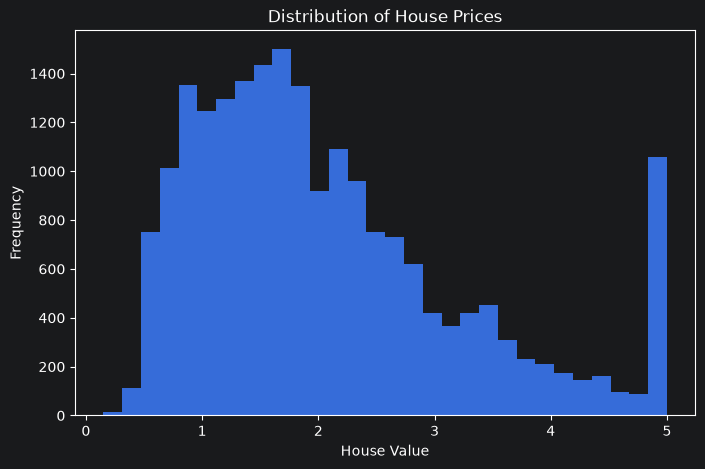

In [12]:
plt.figure(figsize=(8,5))
plt.hist(df['MedHouseVal'], bins=30)
plt.xlabel('House Value')
plt.ylabel('Frequency')
plt.title("Distribution of House Prices")
plt.show()

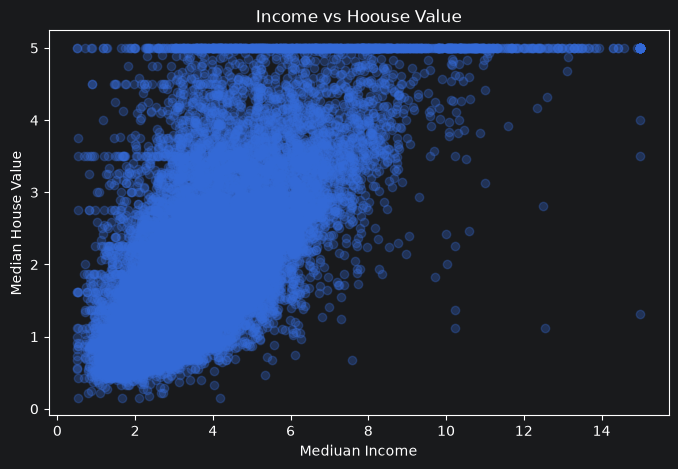

In [13]:
plt.figure(figsize =(8,5))
plt.scatter(df['MedInc'], df['MedHouseVal'], alpha=0.3)
plt.xlabel('Mediuan Income')
plt.ylabel("Median House Value")
plt.title('Income vs Hoouse Value')
plt.show()


In [15]:
X=df.drop('MedHouseVal', axis=1)
Y=df['MedHouseVal']

In [16]:
print("Input Feature Shape:",X.shape)
print('Target Variable Shape:',Y.shape)

Input Feature Shape: (20640, 8)
Target Variable Shape: (20640,)


In [17]:
from sklearn.model_selection import train_test_split
X_train,X_test, Y_train, Y_test= train_test_split(X,Y, test_size=0.2, random_state=42)


In [19]:
print('Training Feature:',X_train.shape)
print('Testing Feature:', X_test.shape)
print('Training Target:',Y_train.shape)
print('Testing Target:', Y_test.shape)


Training Feature: (16512, 8)
Testing Feature: (4128, 8)
Training Target: (16512,)
Testing Target: (4128,)


In [20]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(X_train,Y_train)
print('Intercepts:',model.intercept_)
print('Coefficients:',model.coef_)



Intercepts: -37.023277706064164
Coefficients: [ 4.48674910e-01  9.72425752e-03 -1.23323343e-01  7.83144907e-01
 -2.02962058e-06 -3.52631849e-03 -4.19792487e-01 -4.33708065e-01]


In [21]:
Y_pred=model.predict(X_test)
comparison=pd.DataFrame({
    'Actual Price':Y_test.values,
    'Predicted Price':Y_pred
})
print(comparison.head(10))


   Actual Price  Predicted Price
0       0.47700         0.719123
1       0.45800         1.764017
2       5.00001         2.709659
3       2.18600         2.838926
4       2.78000         2.604657
5       1.58700         2.011754
6       1.98200         2.645500
7       1.57500         2.168755
8       3.40000         2.740746
9       4.46600         3.915615


In [22]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
mae=mean_absolute_error(Y_test, Y_pred)
rmse = np.sqrt(mean_squared_error(Y_test, Y_pred))

r2 = r2_score(Y_test, Y_pred)
print('Mean Absolute Error:',mae)
print('Root Mean Squared Error:',rmse)
print('R2 Score:',r2)






Mean Absolute Error: 0.5332001304956565
Root Mean Squared Error: 0.745581383012776
R2 Score: 0.5757877060324512


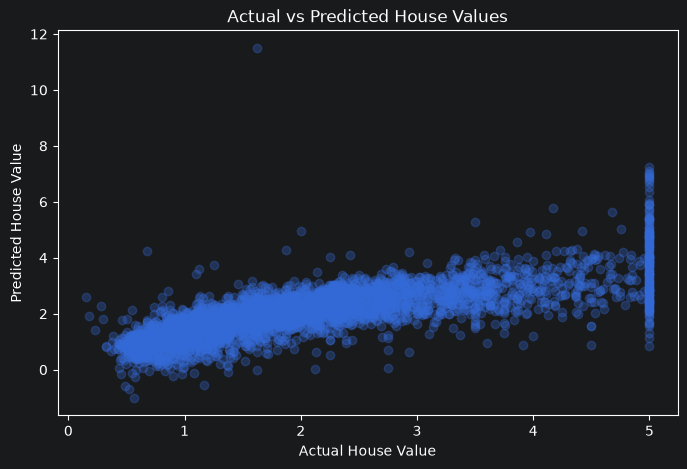

In [24]:
low = min(Y_test.min(), Y_pred.min())
high = max(Y_test.max(), Y_pred.max())

plt.figure(figsize=(8,5))
plt.scatter(Y_test, Y_pred,alpha=0.3)
plt.xlabel('Actual House Value')
plt.ylabel('Predicted House Value')
plt.title('Actual vs Predicted House Values')
plt.show()


In [26]:
import joblib
joblib.dump(model,'House_price_model.pkl')


['House_price_model.pkl']

In [27]:
loaded_model=joblib.load('House_price_model.pkl')
print('Model Loaded Successfully!!')


Model Loaded Successfully!!


In [28]:
new_predictions=loaded_model.predict(X_test)
print("First 5 predictions:", new_predictions[:5])ś


First 5 predictions: [0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]
